# Customer Sales Data Cleaning and Preprocessing

## Introduction

Data cleaning is an important step in the data analysis process. Raw datasets often contain missing values, duplicate records, inconsistent formats, incorrect data types and unusual values that can affect the accuracy of analysis.

This project focuses on cleaning and preprocessing a customer sales dataset using Python. The dataset initially contains 10,200 records and 12 columns, including customer details, purchase information, feedback scores and dates.

The main objective is to identify data-quality issues, apply appropriate cleaning techniques and prepare a more consistent dataset for further analysis.

## Project Objectives

- Identify missing values and duplicate records.
- Handle missing data using suitable strategies.
- Standardise inconsistent categorical values.
- Correct data types and invalid entries.
- Detect and handle outliers using the IQR method.
- Compare data quality before and after cleaning.

## Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/Sahajahanur/end-to-end-data-cleaning-python/main/messy_customer_sales_data.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (10200, 12)


,Customer_ID,Name,Gender,Age,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Email,Phone_Number,Country
0,CUST4371,Paul Wilson,m,52.0,KOLKATA,2025-06-26,2025-05-17,26944.0,1.0,peckvictoria@example.com,2131107701,India
1,CUST5957,Jason Thomas,M,51.0 years,NaN,2021-02-17,2025-07-22,44152.0,2.0,owensanthony@example.com,1080761560,india
2,CUST3754,Brittney Martinez,F,62.0,hyderabad,2023-11-05,2024-12-08,31745.0,2.0,tara39@example.org,8981006345,India
3,CUST2934,Brenda Pierce,FEMALE,40.0,hyderabad,2022-03-13,2025-10-02,39674.0,1.0,berrynancy@example.org,8228064204,india
4,CUST5683,Matthew Carroll,f,41.0,CHENNAI,2024-04-05,2024-12-15,NaN,8.0,denise84@example.org,2665569480,India


In [3]:

print("First 5 rows:")
display(df.head())

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

First 5 rows:


,Customer_ID,Name,Gender,Age,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Email,Phone_Number,Country
0,CUST4371,Paul Wilson,m,52.0,KOLKATA,2025-06-26,2025-05-17,26944.0,1.0,peckvictoria@example.com,2131107701,India
1,CUST5957,Jason Thomas,M,51.0 years,NaN,2021-02-17,2025-07-22,44152.0,2.0,owensanthony@example.com,1080761560,india
2,CUST3754,Brittney Martinez,F,62.0,hyderabad,2023-11-05,2024-12-08,31745.0,2.0,tara39@example.org,8981006345,India
3,CUST2934,Brenda Pierce,FEMALE,40.0,hyderabad,2022-03-13,2025-10-02,39674.0,1.0,berrynancy@example.org,8228064204,india
4,CUST5683,Matthew Carroll,f,41.0,CHENNAI,2024-04-05,2024-12-15,NaN,8.0,denise84@example.org,2665569480,India


Dataset shape: (10200, 12)

Column names:
['Customer_ID', 'Name', 'Gender', 'Age', 'City', 'Signup_Date', 'Last_Purchase_Date', 'Purchase_Amount', 'Feedback_Score', 'Email', 'Phone_Number', 'Country']

Data types:
Customer_ID            object
Name                   object
Gender                 object
Age                    object
City                   object
Signup_Date            object
Last_Purchase_Date     object
Purchase_Amount       float64
Feedback_Score        float64
Email                  object
Phone_Number            int64
Country                object
dtype: object

Missing values:
Customer_ID           1023
Name                     0
Gender                1026
Age                    951
City                  1016
Signup_Date              0
Last_Purchase_Date    1012
Purchase_Amount       1021
Feedback_Score        1023
Email                    0
Phone_Number             0
Country                732
dtype: int64

Duplicate rows: 15


In [4]:
# 1. Missing value percentages
print("MISSING VALUE REPORT")
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})
display(missing_report)

# 2. Unique values in categorical columns
print("\nUNIQUE VALUES")
for col in ["Gender", "City", "Country"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(20))

# 3. Age inspection
print("\nAGE VALUES")
print(df["Age"].value_counts(dropna=False).head(20))

# 4. Numerical statistics
print("\nNUMERICAL SUMMARY")
display(df[["Purchase_Amount", "Feedback_Score"]].describe())

# 5. Date inspection
print("\nDATE SUMMARY")
for col in ["Signup_Date", "Last_Purchase_Date"]:
    dates = pd.to_datetime(df[col], errors="coerce")
    print(f"\n{col}")
    print("Invalid dates:", dates.isna().sum())
    print("Earliest date:", dates.min())
    print("Latest date:", dates.max())

MISSING VALUE REPORT


,Missing Count,Missing Percentage
Customer_ID,1023,10.03
Name,0,0.00
Gender,1026,10.06
Age,951,9.32
City,1016,9.96
Signup_Date,0,0.00
Last_Purchase_Date,1012,9.92
Purchase_Amount,1021,10.01
Feedback_Score,1023,10.03
Email,0,0.00



UNIQUE VALUES

Gender:
Gender
f         1184
M         1171
m         1163
F         1157
MALE      1131
female    1128
male      1121
FEMALE    1119
NaN       1026
Name: count, dtype: int64

City:
City
NaN            1016
 Kolkata        820
 Mumbai         812
 Chennai        784
 Bangalore      773
 Hyderabad      770
 Delhi          763
 CHENNAI        404
 KOLKATA        395
 MUMBAI         393
 hyderabad      384
 bangalore      383
 DELHI          378
 delhi          369
 BANGALORE      363
 HYDERABAD      360
 mumbai         352
 chennai        343
 kolkata        338
Name: count, dtype: int64

Country:
Country
India    7132
IND       793
india     772
InDia     771
NaN       732
Name: count, dtype: int64

AGE VALUES
Age
NaN     951
66.0    197
62.0    194
43.0    188
34.0    186
64.0    185
45.0    185
40.0    183
32.0    182
49.0    182
52.0    181
39.0    179
46.0    178
54.0    178
61.0    177
38.0    177
19.0    176
41.0    175
53.0    175
42.0    174
Name: count, dtype: 

,Purchase_Amount,Feedback_Score
count,9.179000e+03,9177.000000
mean,2.909013e+04,5.479351
std,2.086971e+05,2.867123
min,-5.000000e+02,1.000000
25%,1.229500e+04,3.000000
50%,2.433000e+04,5.000000
75%,3.713000e+04,8.000000
max,9.999999e+06,10.000000



DATE SUMMARY

Signup_Date
Invalid dates: 0
Earliest date: 2020-10-08 00:00:00
Latest date: 2025-10-08 00:00:00

Last_Purchase_Date
Invalid dates: 1012
Earliest date: 2024-10-08 00:00:00
Latest date: 2025-10-08 00:00:00


In [5]:
# Convert Age into numeric values for inspection
age_numeric = pd.to_numeric(
    df["Age"].astype(str).str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

print("AGE CHECK")
print("Invalid or missing ages:", age_numeric.isna().sum())
print("Minimum age:", age_numeric.min())
print("Maximum age:", age_numeric.max())

# Purchase amount checks
print("\nPURCHASE AMOUNT CHECK")
print("Negative amounts:", (df["Purchase_Amount"] < 0).sum())
print("Zero amounts:", (df["Purchase_Amount"] == 0).sum())
print("Amounts above 100000:", (df["Purchase_Amount"] > 100000).sum())

# Feedback score checks
print("\nFEEDBACK SCORE CHECK")
print("Below 1:", (df["Feedback_Score"] < 1).sum())
print("Above 10:", (df["Feedback_Score"] > 10).sum())

# Date chronology check
signup = pd.to_datetime(df["Signup_Date"], errors="coerce")
purchase = pd.to_datetime(df["Last_Purchase_Date"], errors="coerce")

print("\nDATE CHECK")
print("Purchases before signup:", (purchase < signup).sum())

# Outlier detection using IQR
Q1 = df["Purchase_Amount"].quantile(0.25)
Q3 = df["Purchase_Amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("\nIQR OUTLIER CHECK")
print("Lower boundary:", lower)
print("Upper boundary:", upper)
print("Potential outliers:",
      ((df["Purchase_Amount"] < lower) |
       (df["Purchase_Amount"] > upper)).sum())

AGE CHECK
Invalid or missing ages: 1015
Minimum age: 3.0
Maximum age: 250.0

PURCHASE AMOUNT CHECK
Negative amounts: 4
Zero amounts: 7
Amounts above 100000: 4

FEEDBACK SCORE CHECK
Below 1: 0
Above 10: 0

DATE CHECK
Purchases before signup: 936

IQR OUTLIER CHECK
Lower boundary: -24957.5
Upper boundary: 74382.5
Potential outliers: 4


In [6]:

# COMPLETE DATA CLEANING - REPLACEMENT CELL

import pandas as pd
import numpy as np

# Reload original dataset independently
url = "https://raw.githubusercontent.com/Sahajahanur/end-to-end-data-cleaning-python/main/messy_customer_sales_data.csv"
df = pd.read_csv(url)

# Save original quality metrics
before_rows = len(df)
before_duplicates = df.duplicated().sum()
before_missing = df.isnull().sum().sum()

# Create working copy and remove duplicates
cleaned_df = df.drop_duplicates().copy()

# Standardise categorical columns
cleaned_df["Gender"] = (
    cleaned_df["Gender"].astype("string").str.strip().str.upper()
    .replace({"M": "MALE", "F": "FEMALE"})
)

cleaned_df["City"] = (
    cleaned_df["City"].astype("string").str.strip().str.title()
)

cleaned_df["Country"] = (
    cleaned_df["Country"].astype("string").str.strip().str.upper()
    .replace({"IND": "INDIA"})
)

# Clean age
cleaned_df["Age"] = pd.to_numeric(
    cleaned_df["Age"].astype(str).str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)
cleaned_df.loc[~cleaned_df["Age"].between(18, 100), "Age"] = np.nan

# Convert date columns
for col in ["Signup_Date", "Last_Purchase_Date"]:
    cleaned_df[col] = pd.to_datetime(cleaned_df[col], errors="coerce")

# Flag impossible purchase dates
invalid_dates = (
    cleaned_df["Last_Purchase_Date"] < cleaned_df["Signup_Date"]
)
cleaned_df.loc[invalid_dates, "Last_Purchase_Date"] = pd.NaT

# Treat negative purchase amounts as missing
cleaned_df.loc[cleaned_df["Purchase_Amount"] < 0, "Purchase_Amount"] = np.nan

# IQR-based outlier treatment: cap high values, don't delete rows
q1 = cleaned_df["Purchase_Amount"].quantile(0.25)
q3 = cleaned_df["Purchase_Amount"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

cleaned_df["Purchase_Amount"] = cleaned_df["Purchase_Amount"].clip(
    upper=upper_limit
)

# Convert phone number to text
cleaned_df["Phone_Number"] = cleaned_df["Phone_Number"].astype("string")

# Fill missing numeric values with median
for col in ["Age", "Purchase_Amount", "Feedback_Score"]:
    cleaned_df[col] = cleaned_df[col].fillna(cleaned_df[col].median())

# Fill missing categorical values with mode
for col in ["Gender", "City", "Country"]:
    cleaned_df[col] = cleaned_df[col].fillna(cleaned_df[col].mode()[0])

# Preserve missing identifiers and personal details rather than inventing them
# Save cleaned file
cleaned_df.to_csv("cleaned_customer_sales.csv", index=False)

# Before and after report
comparison = pd.DataFrame({
    "Before": [
        before_rows,
        before_duplicates,
        before_missing,
        df["Age"].isna().sum(),
        df["Purchase_Amount"].isna().sum()
    ],
    "After": [
        len(cleaned_df),
        cleaned_df.duplicated().sum(),
        cleaned_df.isnull().sum().sum(),
        cleaned_df["Age"].isna().sum(),
        cleaned_df["Purchase_Amount"].isna().sum()
    ]
}, index=[
    "Rows",
    "Duplicates",
    "Missing values",
    "Missing ages",
    "Missing purchase amounts"
])

print("DATA CLEANING COMPLETED SUCCESSFULLY")
display(comparison)
print("Cleaned dataset shape:", cleaned_df.shape)
print("Saved: cleaned_customer_sales.csv")


DATA CLEANING COMPLETED SUCCESSFULLY


,Before,After
Rows,10200,10185
Duplicates,15,182
Missing values,7804,2969
Missing ages,951,0
Missing purchase amounts,1021,0


Cleaned dataset shape: (10185, 12)
Saved: cleaned_customer_sales.csv


In [7]:
# Remove duplicates created by standardisation
cleaned_df = cleaned_df.drop_duplicates().copy()

# Generate final before-and-after report
comparison = pd.DataFrame({
    "Before Cleaning": [
        len(df),
        df.duplicated().sum(),
        df.isnull().sum().sum()
    ],
    "After Cleaning": [
        len(cleaned_df),
        cleaned_df.duplicated().sum(),
        cleaned_df.isnull().sum().sum()
    ]
}, index=["Total Rows", "Duplicate Rows", "Missing Values"])

display(comparison)

# Save final cleaned dataset
cleaned_df.to_csv("cleaned_customer_sales.csv", index=False)

print("Final cleaned dataset saved successfully!")
print("Final shape:", cleaned_df.shape)

,Before Cleaning,After Cleaning
Total Rows,10200,10003
Duplicate Rows,15,0
Missing Values,7804,2917


Final cleaned dataset saved successfully!
Final shape: (10003, 12)


In [8]:
print("FINAL DATA QUALITY REPORT")

print("\nFinal Dataset Shape:")
print(cleaned_df.shape)

print("\nRemaining Missing Values:")
print(cleaned_df.isnull().sum())

print("\nFinal Data Types:")
print(cleaned_df.dtypes)

print("\nRemaining Duplicates:")
print(cleaned_df.duplicated().sum())

print("\nFinal Dataset Preview:")
display(cleaned_df.head())

FINAL DATA QUALITY REPORT

Final Dataset Shape:
(10003, 12)

Remaining Missing Values:
Customer_ID           1000
Name                     0
Gender                   0
Age                      0
City                     0
Signup_Date              0
Last_Purchase_Date    1917
Purchase_Amount          0
Feedback_Score           0
Email                    0
Phone_Number             0
Country                  0
dtype: int64

Final Data Types:
Customer_ID                   object
Name                          object
Gender                string[python]
Age                          float64
City                  string[python]
Signup_Date           datetime64[ns]
Last_Purchase_Date    datetime64[ns]
Purchase_Amount              float64
Feedback_Score               float64
Email                         object
Phone_Number          string[python]
Country               string[python]
dtype: object

Remaining Duplicates:
0

Final Dataset Preview:


,Customer_ID,Name,Gender,Age,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Email,Phone_Number,Country
0,CUST4371,Paul Wilson,MALE,52.0,Kolkata,2025-06-26,NaT,26944.0,1.0,peckvictoria@example.com,2131107701,INDIA
1,CUST5957,Jason Thomas,MALE,51.0,Mumbai,2021-02-17,2025-07-22,44152.0,2.0,owensanthony@example.com,1080761560,INDIA
2,CUST3754,Brittney Martinez,FEMALE,62.0,Hyderabad,2023-11-05,2024-12-08,31745.0,2.0,tara39@example.org,8981006345,INDIA
3,CUST2934,Brenda Pierce,FEMALE,40.0,Hyderabad,2022-03-13,2025-10-02,39674.0,1.0,berrynancy@example.org,8228064204,INDIA
4,CUST5683,Matthew Carroll,FEMALE,41.0,Chennai,2024-04-05,2024-12-15,24340.0,8.0,denise84@example.org,2665569480,INDIA


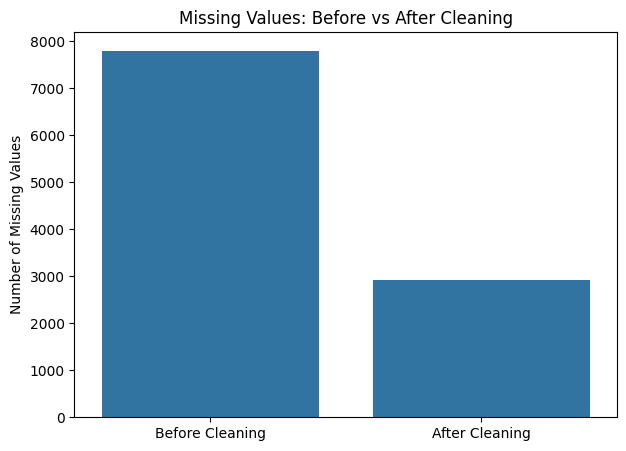

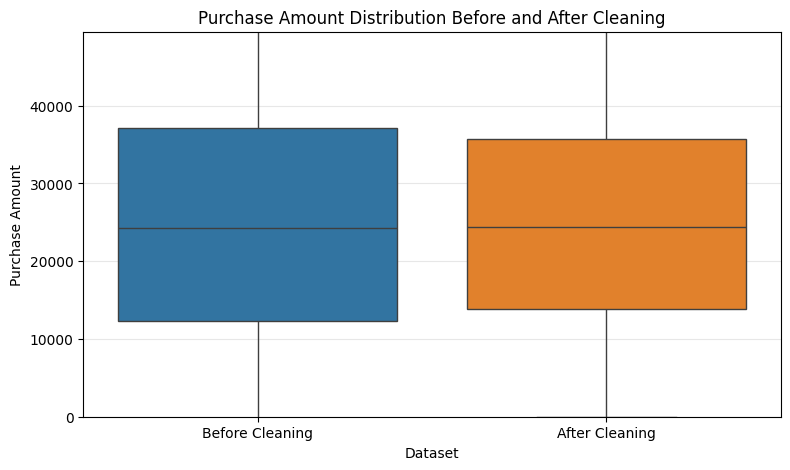

Improved comparison chart generated!
Note: Extreme values above the 99th percentile are hidden for visual clarity.


In [9]:

import matplotlib.pyplot as plt
import seaborn as sns

# Missing values before and after cleaning
missing_before = df.isnull().sum().sum()
missing_after = cleaned_df.isnull().sum().sum()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=["Before Cleaning", "After Cleaning"],
    y=[missing_before, missing_after]
)
plt.title("Missing Values: Before vs After Cleaning")
plt.ylabel("Number of Missing Values")
plt.savefig("missing_values_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


# Improved purchase amount comparison

plt.figure(figsize=(9, 5))

plot_data = pd.DataFrame({
    "Before Cleaning": df["Purchase_Amount"],
    "After Cleaning": cleaned_df["Purchase_Amount"]
})

sns.boxplot(data=plot_data, showfliers=False)

# Zoom the chart to show the main distribution clearly
upper_visual_limit = df["Purchase_Amount"].quantile(0.99)
plt.ylim(bottom=0, top=upper_visual_limit)

plt.title("Purchase Amount Distribution Before and After Cleaning")
plt.ylabel("Purchase Amount")
plt.xlabel("Dataset")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    "purchase_amount_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Improved comparison chart generated!")
print("Note: Extreme values above the 99th percentile are hidden for visual clarity.")



### Visualisation Interpretation

The boxplot compares purchase amounts before and after data cleaning. The original dataset contained extreme values that affected the visual scale. After applying the IQR-based outlier treatment, the distribution became more manageable. The improved visualisation focuses on the central 99% of the original purchase amounts to make the comparison clearer.



## Key Findings and Observations

1. The original dataset contained 10,200 records and 12 columns.
2. Fifteen exact duplicate rows were identified initially. Further duplicates were detected after standardising inconsistent category formats.
3. Missing values were present in customer identifiers, gender, age, city, purchase dates, purchase amounts, feedback scores and country.
4. Gender, city and country values were standardised to consistent formats.
5. Invalid ages and negative purchase amounts were treated as missing values.
6. Date values were converted into datetime format, and purchase dates preceding signup dates were treated as invalid.
7. Extreme purchase amounts were handled using the IQR method.
8. The final dataset contains 10,003 records, zero duplicate rows and 2,917 remaining missing values.

## Conclusion

The data-cleaning process improved the consistency and reliability of the customer sales dataset. Missing values were handled using appropriate strategies, inconsistent categorical values were standardised, and invalid records were investigated. The cleaned dataset is now more suitable for further analysis.
